# Ejercicio 04 · CNN reproducible con Fashion-MNIST

Esta ejecución compara el baseline denso y la CNN sobre una partición fija. Las figuras y métricas se generan desde los scripts reutilizables del proyecto.

**Antes de empezar:** instala las dependencias con `uv sync --extra cpu` (local) o `%pip install -r requirements-colab.txt` (Colab). La primera descarga del dataset requiere conexión a Internet.

In [1]:
from pathlib import Path
import json, subprocess, sys
ROOT = Path.cwd()
if not (ROOT / 'scripts' / 'train_cv.py').exists():
    ROOT = ROOT.parent
assert (ROOT / 'scripts' / 'train_cv.py').exists(), 'Abra el notebook desde la raíz del proyecto.'
print('Proyecto:', ROOT.resolve())

Proyecto: C:\Users\reyti\OneDrive\Documentos\ChatGPT\Tareas\INF8239_U02_CV_Proyecto_Entrega


## 1. Entrenamiento y evidencia

El comando crea el split y su auditoría, entrena ambos modelos y guarda métricas, curvas, matriz de confusión y errores. Si deseas una ejecución rápida de diagnóstico, cambia `--epochs 8` por un número menor; registra esa decisión en el informe final.

In [2]:
# El entrenamiento completo se lanza aquí al cambiar RUN_TRAINING a True.
# En esta entrega los artefactos se generaron con scripts/train_cv.py antes de ejecutar el notebook.
RUN_TRAINING = False
if RUN_TRAINING:
    subprocess.run([sys.executable, str(ROOT / 'scripts' / 'train_cv.py'), '--epochs', '8'], cwd=ROOT, check=True)
else:
    assert (ROOT / 'reports' / 'cv_metrics.json').exists(), 'Ejecute primero scripts/train_cv.py --epochs 8.'
    print('Mostrando resultados guardados en reports/.')

Mostrando resultados guardados en reports/.


## 2. Comparación y limitaciones

Lee resultados únicamente después de que la celda de entrenamiento termine. El test oficial se utiliza una vez al final para evaluar; no debe elegirse arquitectura o hiperparámetros mirando su resultado.

dense {'accuracy': 0.8618, 'f1_macro': 0.8604986358763013, 'parameters': 50890, 'model_size_kib': 619.10546875, 'train_seconds': 10.0870100000011, 'inference': {'batch_size': 256, 'repeats': 5, 'ms_per_image_mean': 0.2953213281244871, 'ms_per_image_std': 0.026817999090974005}}
cnn {'accuracy': 0.7891, 'f1_macro': 0.7845902628821102, 'parameters': 19466, 'model_size_kib': 262.1474609375, 'train_seconds': 59.286518400000205, 'inference': {'batch_size': 256, 'repeats': 5, 'ms_per_image_mean': 0.6080814843741678, 'ms_per_image_std': 0.08619870693970332}}
Comparación: {'f1_macro_delta_cnn_minus_dense': -0.07590837299419106, 'accuracy_delta_cnn_minus_dense': -0.07269999999999999, 'parameter_reduction_cnn_percent': 61.748870112006294, 'size_reduction_cnn_percent': 57.657059391385005, 'training_time_ratio_cnn_over_dense': 5.87751161146799, 'inference_latency_ratio_cnn_over_dense': 2.0590503511410545, 'selected_model_by_validation_f1': 'dense'}


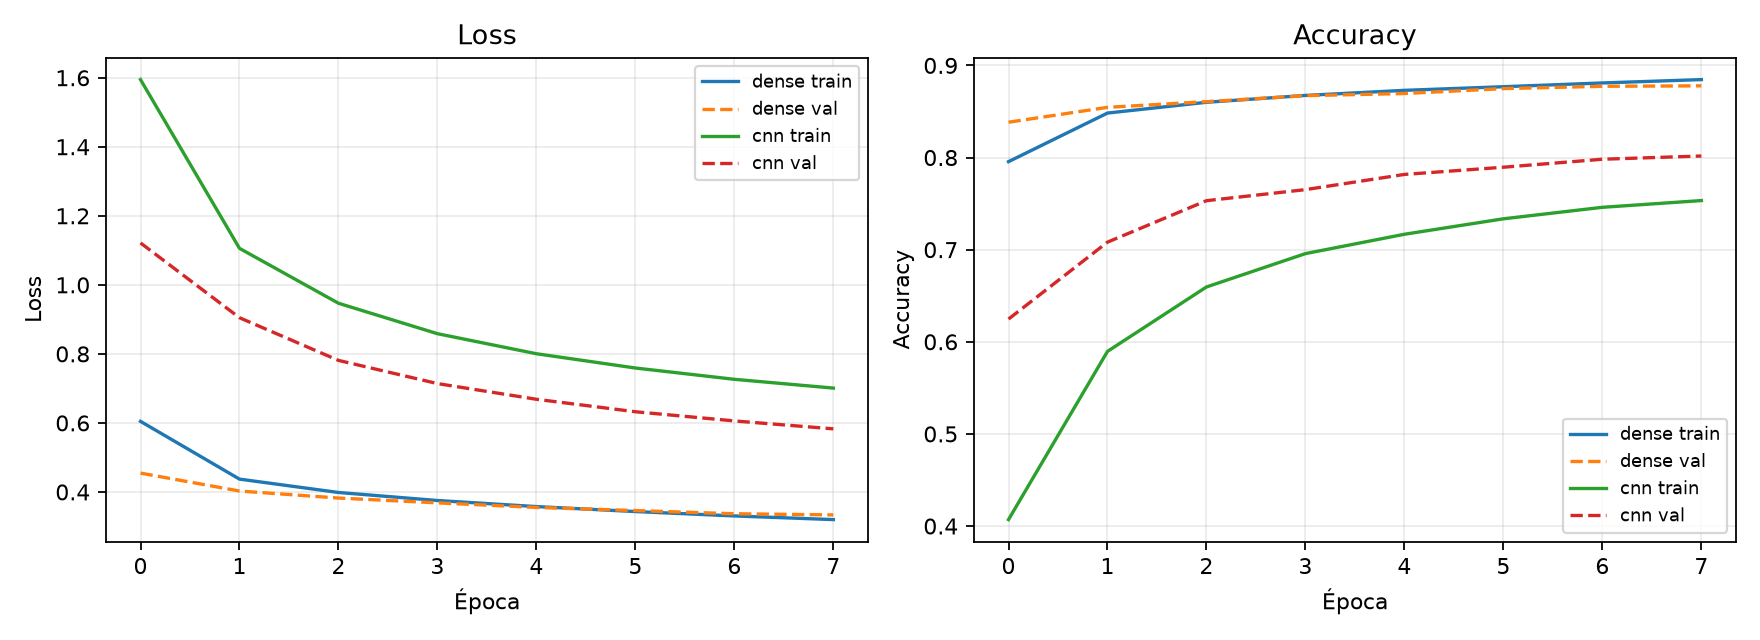

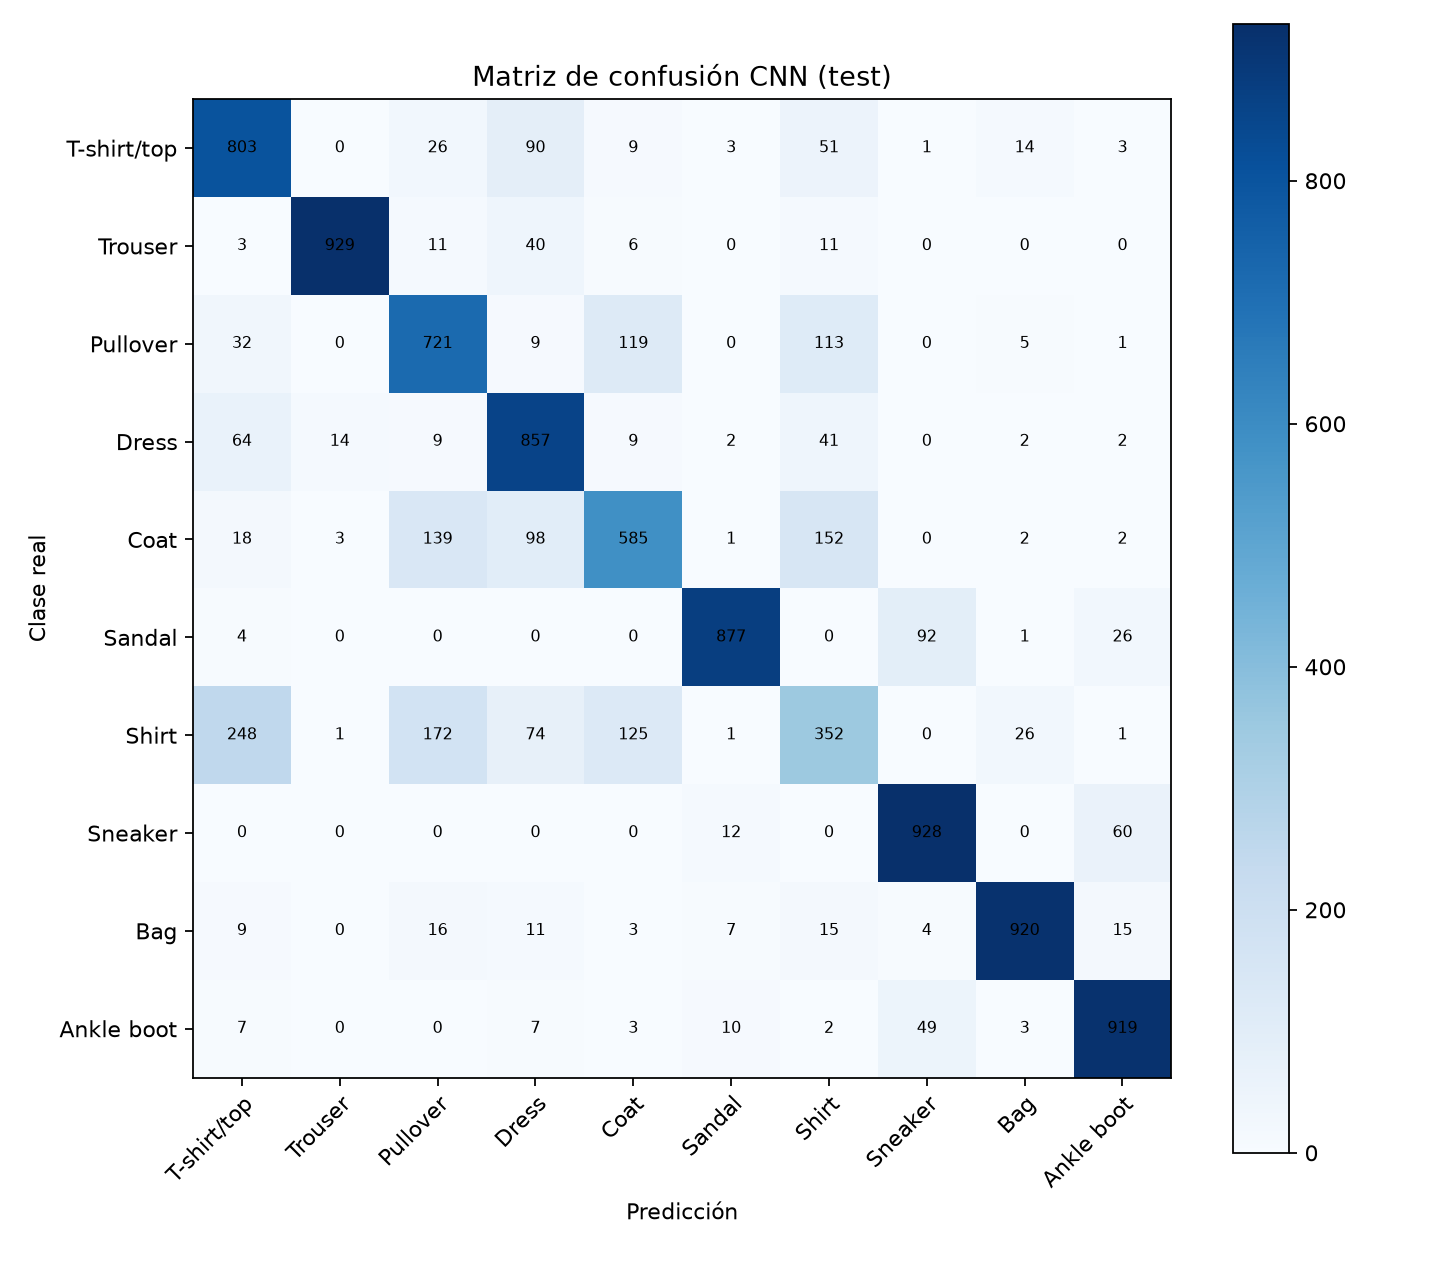

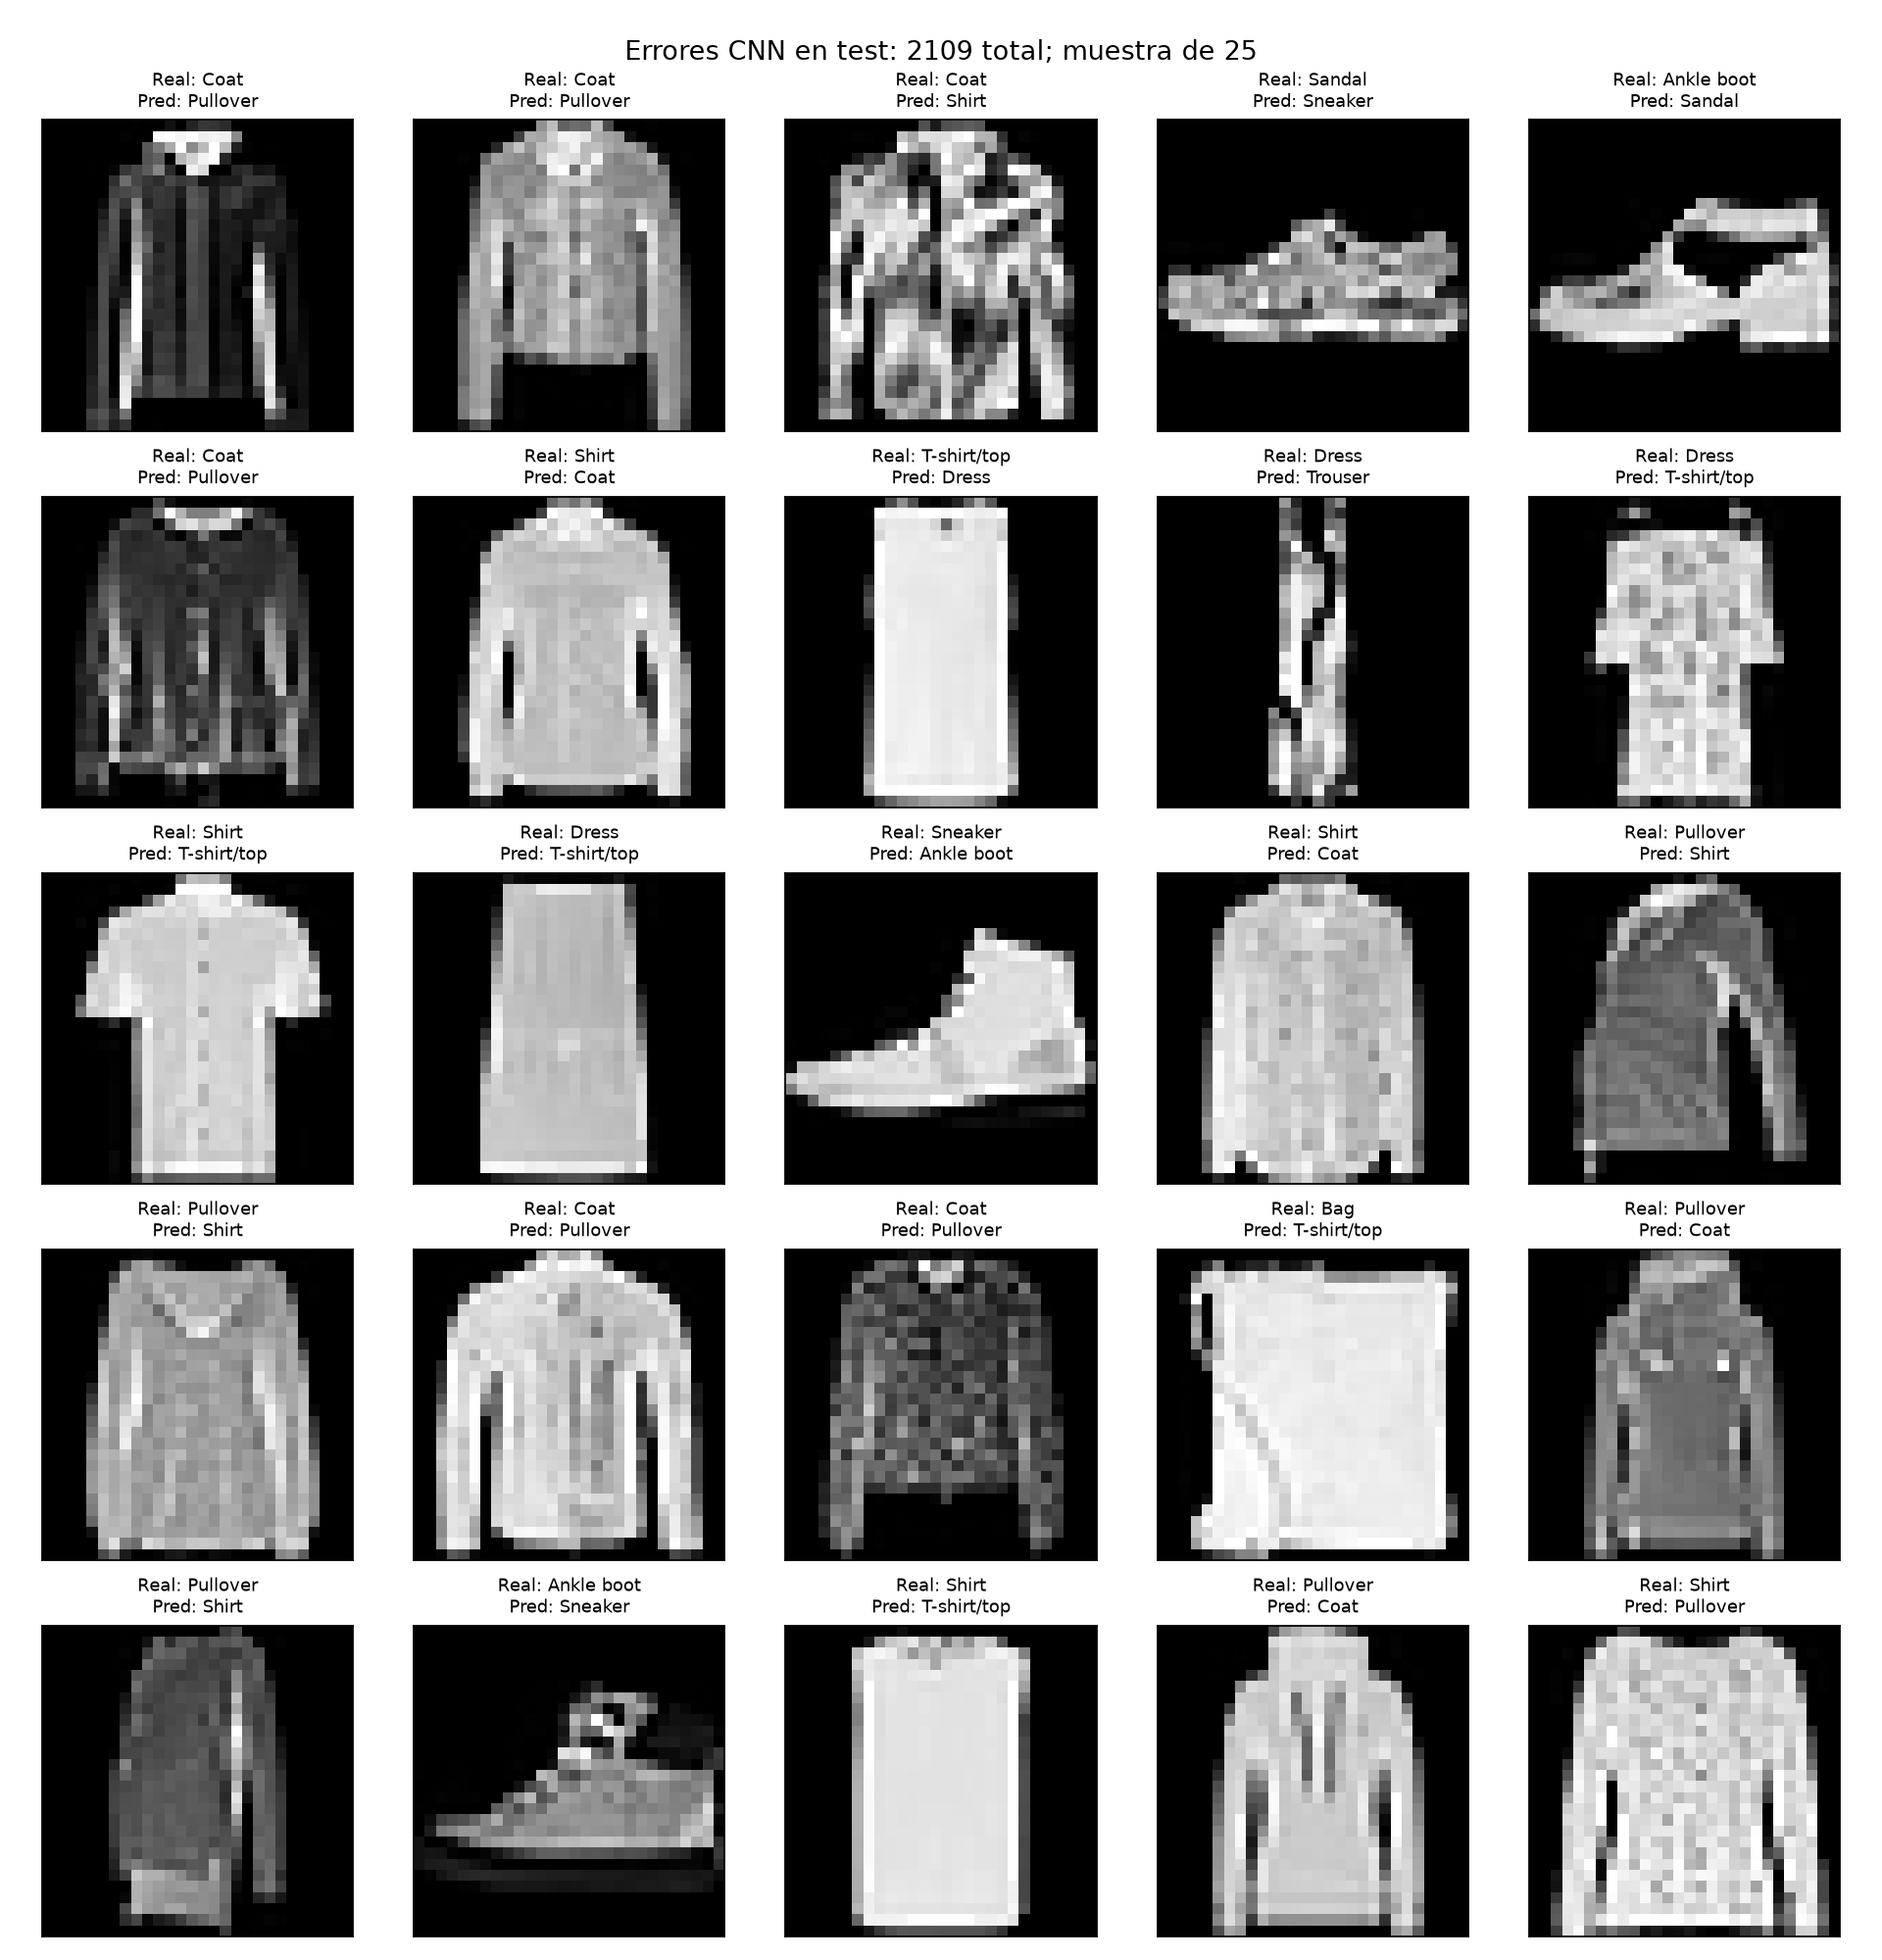

Auditoría: dict_keys(['train', 'validation', 'test'])


In [3]:
from IPython.display import display, Image
metrics = json.loads((ROOT / 'reports' / 'cv_metrics.json').read_text(encoding='utf-8'))
for model, row in metrics['models'].items():
    print(model, {k: row[k] for k in ['accuracy','f1_macro','parameters','model_size_kib','train_seconds','inference']})
print('Comparación:', metrics['comparison'])
display(Image(filename=str(ROOT / 'reports' / 'training_curves.png')))
display(Image(filename=str(ROOT / 'reports' / 'confusion_cnn.png')))
display(Image(filename=str(ROOT / 'reports' / 'cnn_errors.png')))
print('Auditoría:', json.loads((ROOT / 'reports' / 'data_audit.json').read_text())['splits'].keys())

## 3. Interpretación del estudiante

Completa antes de entregar: resultado principal, evidencia predictiva, clase más difícil, costo comparado, si la mejora justifica el costo, limitación del benchmark y qué validarías antes de usar otro dominio. Consulta `MODEL_CARD.md` y `docs/AI_USAGE.md`.